# 02 — Model Training & Evaluation

**SolarVision — 24h-ahead PV power forecast (+ optional nowcast benchmark)**

### Requirements covered
- ≥ 3 model families: **Ridge (linear)**, **Random Forest + LightGBM (trees)**, **LSTM (deep)**
- **MLflow** experiment tracking
- **Optuna** systematic tuning (LightGBM)
- Metrics: **MAE, RMSE, MAPE (daytime), R²**
- **SHAP** global explanations
- Persistence baseline
- Honest comparison with limits of the Laghouat data

### Run order
1. `01_preprocessing.ipynb` → writes `processed_data/forecast_ready.parquet`
2. This notebook

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import lightgbm as lgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

import mlflow
import mlflow.sklearn
import mlflow.lightgbm

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DATA_PATH = Path("processed_data/forecast_ready.parquet")
META_PATH = Path("processed_data/preprocessing_meta.json")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

MLFLOW_DB = "sqlite:///mlflow_solarvision.db"
EXPERIMENT = "solarvision_forecast_24h"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## 1. Load processed data

In [2]:
df = pd.read_parquet(DATA_PATH)
with open(META_PATH, encoding="utf-8") as f:
    meta = json.load(f)

features = meta["features_24h"]
target = "target_24h"

train_df = df[df["split"] == "train"]
val_df   = df[df["split"] == "val"]
test_df  = df[df["split"] == "test"]

X_train, y_train = train_df[features], train_df[target]
X_val,   y_val   = val_df[features],   val_df[target]
X_test,  y_test  = test_df[features],  test_df[target]

day_train = train_df["is_daytime"].values.astype(bool)
day_val   = val_df["is_daytime"].values.astype(bool)
day_test  = test_df["is_daytime"].values.astype(bool)

print("Train/Val/Test:", X_train.shape, X_val.shape, X_test.shape)
print("Daytime hours — val:", day_val.sum(), " test:", day_test.sum())

Train/Val/Test: (2990, 47) (640, 47) (642, 47)
Daytime hours — val: 357  test: 353


## 2. Metrics (daytime MAPE to avoid night zeros)

In [3]:
def regression_metrics(y_true, y_pred, name, daytime_mask=None):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2   = r2_score(y_true, y_pred)

    if daytime_mask is None:
        daytime_mask = y_true > 0.5
    else:
        daytime_mask = np.asarray(daytime_mask, dtype=bool)

    yt, yp = y_true[daytime_mask], y_pred[daytime_mask]
    ok = yt > 0.5
    mape = np.mean(np.abs((yt[ok] - yp[ok]) / yt[ok])) * 100 if ok.sum() else np.nan

    # daytime-only error (closer to MATLAB evaluation style)
    mae_day  = mean_absolute_error(yt, yp) if len(yt) else np.nan
    rmse_day = mean_squared_error(yt, yp) ** 0.5 if len(yt) else np.nan
    r2_day   = r2_score(yt, yp) if len(yt) > 1 else np.nan

    return {
        "model": name,
        "MAE": mae, "RMSE": rmse, "MAPE_day": mape, "R2": r2,
        "MAE_day": mae_day, "RMSE_day": rmse_day, "R2_day": r2_day,
        "n_day": int(daytime_mask.sum()),
    }

def print_metrics(m):
    print(
        f"{m['model']:28s}  MAE={m['MAE']:.3f}  RMSE={m['RMSE']:.3f}  "
        f"MAPE_day={m['MAPE_day']:.1f}%  R2={m['R2']:.4f}  |  "
        f"RMSE_day={m['RMSE_day']:.3f}  R2_day={m['R2_day']:.4f}"
    )

## 3. MLflow setup

In [4]:
mlflow.set_tracking_uri(MLFLOW_DB)
mlflow.set_experiment(EXPERIMENT)
print("MLflow:", mlflow.get_tracking_uri())

MLflow: sqlite:///mlflow_solarvision.db


## 4. Baseline — Persistence (lag 24h)

Strong on PV because of daily cycle. Must always be reported.

In [5]:
persist_col = "P_dusty_same_hour_yesterday"
if persist_col not in X_val.columns:
    persist_col = "P_dusty_W_lag_24h"

persist_val  = X_val[persist_col].values
persist_test = X_test[persist_col].values

m_persist_val  = regression_metrics(y_val,  persist_val,  "Persistence-24h (val)",  day_val)
m_persist_test = regression_metrics(y_test, persist_test, "Persistence-24h (test)", day_test)
print_metrics(m_persist_val)
print_metrics(m_persist_test)

Persistence-24h (val)         MAE=0.919  RMSE=3.538  MAPE_day=11.6%  R2=0.9670  |  RMSE_day=4.737  R2_day=0.9482
Persistence-24h (test)        MAE=1.038  RMSE=3.269  MAPE_day=11.4%  R2=0.9776  |  RMSE_day=4.408  R2_day=0.9623


## 5. Family A — Linear baseline (Ridge)

In [6]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=RANDOM_STATE))

with mlflow.start_run(run_name="ridge_24h"):
    ridge.fit(X_train, y_train)
    pred_val = ridge.predict(X_val)
    m_ridge = regression_metrics(y_val, pred_val, "Ridge (val)", day_val)
    print_metrics(m_ridge)
    mlflow.log_params({"family": "linear", "alpha": 1.0, "n_features": len(features)})
    mlflow.log_metrics({k: float(v) for k, v in m_ridge.items() if k not in ("model",) and v == v})
    mlflow.sklearn.log_model(ridge, "model")

2026/10/25 18:25:13 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Ridge (val)                   MAE=2.820  RMSE=3.788  MAPE_day=45.1%  R2=0.9622  |  RMSE_day=4.346  R2_day=0.9564


## 6. Family B — Tree ensembles

In [7]:
rf = RandomForestRegressor(
    n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1
)

with mlflow.start_run(run_name="random_forest_24h"):
    rf.fit(X_train, y_train)
    pred_val = rf.predict(X_val)
    m_rf = regression_metrics(y_val, pred_val, "RandomForest (val)", day_val)
    print_metrics(m_rf)
    mlflow.log_params({"family": "tree", "n_estimators": 300, "min_samples_leaf": 5})
    mlflow.log_metrics({k: float(v) for k, v in m_rf.items() if k not in ("model",) and v == v})
    mlflow.sklearn.log_model(
    rf,
    artifact_path="model",
    skops_trusted_types=["sklearn.tree._tree.Tree"],
    )

2026/10/25 18:25:28 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


RandomForest (val)            MAE=1.207  RMSE=3.060  MAPE_day=14.5%  R2=0.9753  |  RMSE_day=4.097  R2_day=0.9613


In [8]:
# LightGBM default
lgbm_default = lgb.LGBMRegressor(
    n_estimators=400, learning_rate=0.05, num_leaves=31,
    subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1,
)

with mlflow.start_run(run_name="lightgbm_default_24h"):
    lgbm_default.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(30, verbose=False)],
    )
    pred_val = lgbm_default.predict(X_val)
    m_lgbm = regression_metrics(y_val, pred_val, "LightGBM-default (val)", day_val)
    print_metrics(m_lgbm)
    mlflow.log_params({"family": "tree", "variant": "default"})
    mlflow.log_metrics({k: float(v) for k, v in m_lgbm.items() if k not in ("model",) and v == v})
    mlflow.lightgbm.log_model(lgbm_default, "model")

2026/10/25 18:25:39 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


LightGBM-default (val)        MAE=1.228  RMSE=3.137  MAPE_day=14.9%  R2=0.9741  |  RMSE_day=4.199  R2_day=0.9593


### Optuna tuning for LightGBM (TimeSeriesSplit on train)

In [9]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 800),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 16, 96),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "random_state": RANDOM_STATE,
        "verbose": -1,
    }
    tscv = TimeSeriesSplit(n_splits=3)
    rmses = []
    X_tr_np, y_tr_np = X_train.values, y_train.values
    for tr_idx, va_idx in tscv.split(X_tr_np):
        model = lgb.LGBMRegressor(**params)
        model.fit(X_tr_np[tr_idx], y_tr_np[tr_idx])
        pred = model.predict(X_tr_np[va_idx])
        rmses.append(mean_squared_error(y_tr_np[va_idx], pred) ** 0.5)
    return float(np.mean(rmses))


study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=25, show_progress_bar=True)
print("Best params:", study.best_params)
print("Best CV RMSE:", study.best_value)

Best trial: 14. Best value: 9.68654: 100%|██████████| 25/25 [00:31<00:00,  1.25s/it]

Best params: {'n_estimators': 236, 'learning_rate': 0.013696261634001679, 'num_leaves': 29, 'min_child_samples': 41, 'subsample': 0.982406686369291, 'colsample_bytree': 0.7171665405292557, 'reg_lambda': 3.742365388930496}
Best CV RMSE: 9.686544038686433


In [10]:
best_params = {**study.best_params, "random_state": RANDOM_STATE, "verbose": -1}
lgbm_opt = lgb.LGBMRegressor(**best_params)

with mlflow.start_run(run_name="lightgbm_optuna_24h"):
    lgbm_opt.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(40, verbose=False)],
    )
    pred_val = lgbm_opt.predict(X_val)
    m_lgbm_opt = regression_metrics(y_val, pred_val, "LightGBM-Optuna (val)", day_val)
    print_metrics(m_lgbm_opt)
    mlflow.log_params({**best_params, "family": "tree", "variant": "optuna"})
    mlflow.log_metrics({k: float(v) for k, v in m_lgbm_opt.items() if k not in ("model",) and v == v})
    mlflow.lightgbm.log_model(lgbm_opt, "model")

2026/10/25 18:26:21 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


LightGBM-Optuna (val)         MAE=1.599  RMSE=3.200  MAPE_day=20.4%  R2=0.9730  |  RMSE_day=4.257  R2_day=0.9582


## 7. Family C — Deep learning (LSTM on lag window)

Uses a fixed set of power lags as a short sequence (no extra data beyond the CSV).

In [11]:
LAG_FEATS = [c for c in [
    "P_dusty_W_lag_1h", "P_dusty_W_lag_3h", "P_dusty_W_lag_6h",
    "P_dusty_W_lag_12h", "P_dusty_W_lag_24h", "P_dusty_W_lag_48h", "P_dusty_W_lag_72h",
] if c in features]

STATIC_FEATS = [c for c in features if c not in LAG_FEATS]


def build_seq_matrices(frame):
    # sequence: (batch, seq=len(LAG_FEATS), 1) sorted by lag length roughly
    seq = frame[LAG_FEATS].values.astype(np.float32)[:, :, None]  # weak sequential signal
    static = frame[STATIC_FEATS].values.astype(np.float32)
    return seq, static


class HybridLSTM(nn.Module):
    def __init__(self, n_static, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, num_layers=2, batch_first=True, dropout=0.2)
        self.head = nn.Sequential(
            nn.Linear(hidden + n_static, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1),
        )

    def forward(self, seq, static):
        out, _ = self.lstm(seq)
        h = out[:, -1, :]
        return self.head(torch.cat([h, static], dim=1)).squeeze(-1)


def train_lstm(train_frame, val_frame, epochs=40, lr=1e-3, patience=8):
    # scale static + target using train only
    sc_x = StandardScaler().fit(train_frame[STATIC_FEATS])
    sc_y = StandardScaler().fit(train_frame[[target]])

    def pack(frame):
        seq, _ = build_seq_matrices(frame)
        st = sc_x.transform(frame[STATIC_FEATS]).astype(np.float32)
        y  = sc_y.transform(frame[[target]]).ravel().astype(np.float32)
        return (
            torch.tensor(seq), torch.tensor(st), torch.tensor(y)
        )

    tr_seq, tr_st, tr_y = pack(train_frame)
    va_seq, va_st, va_y = pack(val_frame)

    train_loader = DataLoader(TensorDataset(tr_seq, tr_st, tr_y), batch_size=64, shuffle=False)
    model = HybridLSTM(n_static=len(STATIC_FEATS)).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.MSELoss()

    best_state, best_val, wait = None, float("inf"), 0
    for ep in range(1, epochs + 1):
        model.train()
        for xs, xst, yy in train_loader:
            xs, xst, yy = xs.to(device), xst.to(device), yy.to(device)
            opt.zero_grad()
            loss = crit(model(xs, xst), yy)
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            vloss = crit(
                model(va_seq.to(device), va_st.to(device)), va_y.to(device)
            ).item()
        if vloss < best_val:
            best_val, best_state, wait = vloss, {k: v.cpu().clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)

    def predict(frame):
        seq, _ = build_seq_matrices(frame)
        st = sc_x.transform(frame[STATIC_FEATS]).astype(np.float32)
        model.eval()
        with torch.no_grad():
            pred_n = model(torch.tensor(seq).to(device), torch.tensor(st).to(device)).cpu().numpy()
        return sc_y.inverse_transform(pred_n.reshape(-1, 1)).ravel()

    return model, predict


print("Training LSTM...")
lstm_model, lstm_predict = train_lstm(train_df, val_df)
pred_val_lstm = lstm_predict(val_df)
m_lstm = regression_metrics(y_val, pred_val_lstm, "LSTM (val)", day_val)
print_metrics(m_lstm)

with mlflow.start_run(run_name="lstm_24h"):
    mlflow.log_params({"family": "deep", "hidden": 64, "layers": 2})
    mlflow.log_metrics({k: float(v) for k, v in m_lstm.items() if k not in ("model",) and v == v})

Training LSTM...
LSTM (val)                    MAE=1.571  RMSE=3.017  MAPE_day=22.2%  R2=0.9760  |  RMSE_day=3.950  R2_day=0.9640


## 8. Validation leaderboard + select final model

In [12]:
board = pd.DataFrame([
    m_persist_val, m_ridge, m_rf, m_lgbm, m_lgbm_opt, m_lstm
]).sort_values("MAE")

print("=== Validation leaderboard (sorted by MAE) ===")
display_cols = ["model", "MAE", "RMSE", "MAPE_day", "R2", "RMSE_day", "R2_day"]
print(board[display_cols].to_string(index=False))

board.to_csv("model_comparison_val_24h.csv", index=False)

# Select best *learned* model by validation MAE (exclude pure persistence for deployment artifact,
# but always report persistence). Prefer Optuna LGBM if close.
learned = board[~board["model"].str.contains("Persistence")].copy()
best_row = learned.iloc[0]
print("\nSelected learned model:", best_row["model"])

=== Validation leaderboard (sorted by MAE) ===
                 model      MAE     RMSE  MAPE_day       R2  RMSE_day   R2_day
 Persistence-24h (val) 0.918516 3.537821 11.648265 0.967016  4.736828 0.948215
    RandomForest (val) 1.207310 3.059737 14.452782 0.975328  4.096681 0.961266
LightGBM-default (val) 1.228308 3.136719 14.926587 0.974071  4.198826 0.959310
            LSTM (val) 1.570505 3.017398 22.199763 0.976006  3.950080 0.963988
 LightGBM-Optuna (val) 1.599241 3.199869 20.387469 0.973016  4.257418 0.958167
           Ridge (val) 2.820252 3.787765 45.140171 0.962190  4.346463 0.956398

Selected learned model: RandomForest (val)


In [13]:
# Map name → object
candidates = {
    "Ridge (val)": ridge,
    "RandomForest (val)": rf,
    "LightGBM-default (val)": lgbm_default,
    "LightGBM-Optuna (val)": lgbm_opt,
}

final_name = best_row["model"]
if "LSTM" in final_name:
    # keep tree model for easy joblib export; LSTM optional artifact
    final_model = lgbm_opt
    final_name = "LightGBM-Optuna (val)"
    print("LSTM best on MAE but exporting LightGBM-Optuna for stable serving.")
else:
    final_model = candidates[final_name]

print("Exporting:", final_name)

Exporting: RandomForest (val)


## 9. Hold-out TEST (once) + optional blend with persistence

In [14]:
pred_test_model = final_model.predict(X_test)
m_test_model = regression_metrics(y_test, pred_test_model, f"{final_name} → TEST", day_test)
print_metrics(m_test_model)
print_metrics(m_persist_test)

# Simple validated blend weight on VAL set
pred_val_model = final_model.predict(X_val)
ws = np.linspace(0, 1, 11)
blend_scores = []
for w in ws:
    blend = w * pred_val_model + (1 - w) * persist_val
    blend_scores.append((w, mean_absolute_error(y_val, blend)))
w_best = min(blend_scores, key=lambda t: t[1])[0]
print(f"Best persistence blend weight on val: w_model={w_best:.2f}")

pred_test_blend = w_best * pred_test_model + (1 - w_best) * persist_test
m_test_blend = regression_metrics(y_test, pred_test_blend, f"Blend w={w_best:.2f} → TEST", day_test)
print_metrics(m_test_blend)

test_board = pd.DataFrame([m_persist_test, m_test_model, m_test_blend])
test_board.to_csv("model_comparison_test_24h.csv", index=False)
print(test_board[display_cols].to_string(index=False))

RandomForest (val) → TEST     MAE=1.744  RMSE=3.748  MAPE_day=15.3%  R2=0.9705  |  RMSE_day=5.054  R2_day=0.9504
Persistence-24h (test)        MAE=1.038  RMSE=3.269  MAPE_day=11.4%  R2=0.9776  |  RMSE_day=4.408  R2_day=0.9623
Best persistence blend weight on val: w_model=0.20
Blend w=0.20 → TEST           MAE=1.068  RMSE=3.135  MAPE_day=11.2%  R2=0.9794  |  RMSE_day=4.228  R2_day=0.9653
                    model      MAE     RMSE  MAPE_day       R2  RMSE_day   R2_day
   Persistence-24h (test) 1.038271 3.268983 11.436827 0.977563  4.408471 0.962293
RandomForest (val) → TEST 1.744260 3.747669 15.260261 0.970511  5.053973 0.950442
      Blend w=0.20 → TEST 1.068438 3.135334 11.201624 0.979361  4.228232 0.965313


## 10. SHAP (global explanation on validation sample)

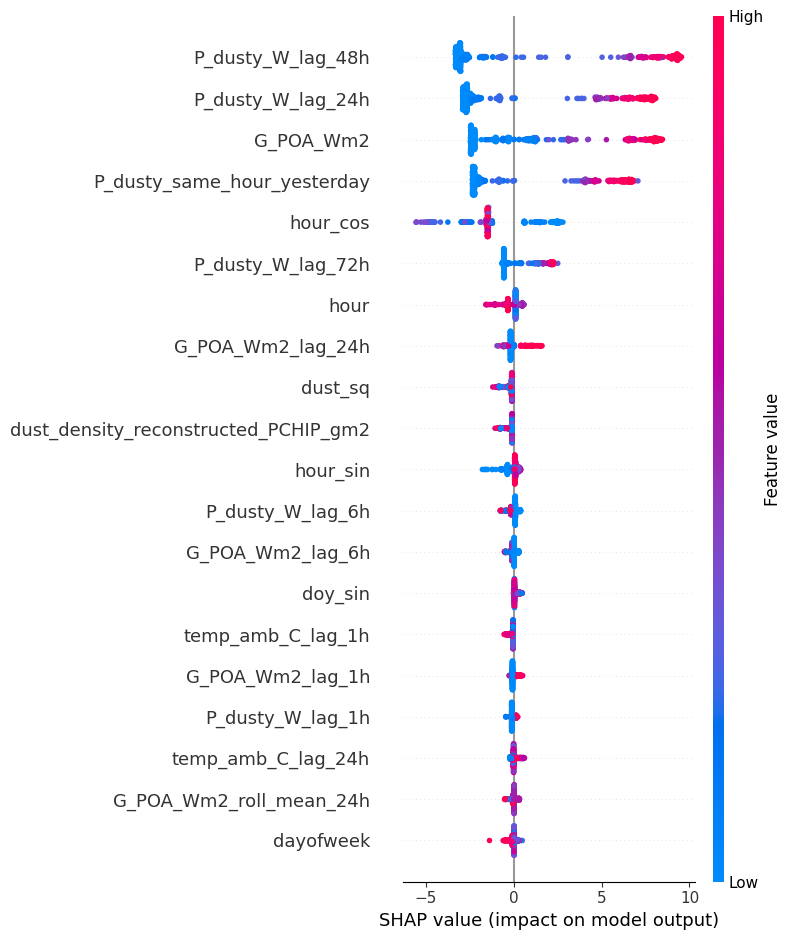

Saved figures/shap_summary_24h.png


In [15]:
import shap

explain_model = final_model
sample = X_val.sample(n=min(400, len(X_val)), random_state=RANDOM_STATE)

try:
    explainer = shap.TreeExplainer(explain_model)
    shap_values = explainer.shap_values(sample)
except Exception:
    explainer = shap.Explainer(explain_model.predict, sample)
    shap_values = explainer(sample)

plt.figure()
shap.summary_plot(shap_values, sample, show=False, max_display=20)
plt.tight_layout()
plt.savefig(FIG_DIR / "shap_summary_24h.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved figures/shap_summary_24h.png")

## 11. Save artifacts for anomaly notebook

In [16]:
joblib.dump(final_model, MODEL_DIR / "best_forecast_24h.joblib")
joblib.dump(features, MODEL_DIR / "best_forecast_24h_features.joblib")
joblib.dump({"blend_w_model": float(w_best), "persist_col": persist_col}, MODEL_DIR / "blend_config.joblib")

# Full test predictions table for anomaly module
results = test_df.copy()
results["actual_power_W"] = y_test.values
results["predicted_power_W"] = pred_test_model
results["predicted_blend_W"] = pred_test_blend
results["residual_W"] = results["actual_power_W"] - results["predicted_power_W"]
results["residual_pct"] = np.where(
    np.abs(results["predicted_power_W"]) > 0.5,
    results["residual_W"] / results["predicted_power_W"] * 100,
    np.nan,
)
results[[
    "actual_power_W", "predicted_power_W", "predicted_blend_W",
    "residual_W", "residual_pct", "is_daytime", "P_clean_W" if "P_clean_W" in results.columns else "actual_power_W"
]].to_csv("forecast_test_predictions_24h.csv")

print("Saved models/ and forecast_test_predictions_24h.csv")
print("Done.")

Saved models/ and forecast_test_predictions_24h.csv
Done.


## Interpretation notes (for documentation)

1. **Persistence is a mandatory baseline** on this dataset because of strong daily seasonality.
2. If the learned model does not beat persistence on the single final test window, report both numbers; consider the **blend** and multi-window tests in future work.
3. Daytime metrics are the fair operational view (night MAPE is misleading).
4. Dust features exist in the CSV but may contribute less than lags for *24h-ahead* prediction; that is a data/task property, not a pipeline error.
5. MATLAB Seghir results are **nowcast-style** and not a direct numeric target for 24h-ahead RMSE.